In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
from sklearn.metrics import accuracy_score
from tqdm.auto import tqdm

from algorithms.tmc_shapley import tmc_shapley
from algorithms.group_tested_shapley import group_testing_shapley
from algorithms.loo import leave_one_out
from algorithms.random_sampling import random_valuation
from algorithms.least_core import montecarlo_least_core
from algorithms.nucleolus import montecarlo_nucleolus
from algorithms.banzhaf import montecarlo_banzhaf_index
from models.train_model import get_model

import time
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import seaborn as sns

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [86]:
DATASET_NAME = "synthetic_data"
MODEL_NAME = "logistic"
SCORING = "accuracy"
N_MC_ITERATIONS = 100
RANDOM_STATE = 42

OUTPUT_DIR = Path(f"./output/data_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [87]:
def load_dataset(name):
    if name == "dog_vs_fish":
        path = Path("../datasets/dog_vs_fish/dog_vs_fish_dataset.npz")
    elif name == "synthetic_data":
        path = Path("../datasets/synthetic_data/synethetic_dataset.npz")
    elif name == "apple_quality":
        path = Path("../datasets/apple_quality/apple_quality_preprocessed.npz")
    elif name == "congress":
        path = Path("../datasets/congress/congress_preprocessed.npz")

    else:
        raise ValueError(f"Unknown dataset: {name}")

    data = np.load(path)
    return data["X_train"], data["X_test"], data["y_train"], data["y_test"]

X_train, X_test, y_train, y_test = load_dataset(DATASET_NAME)
logger.info(f" dataset: X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

In [88]:
def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

scorer = get_scorer(SCORING)

In [89]:
class DataWrapper:

    def __init__(self, length, data_names=None):
        self.indices = list(range(length))
        self.data_names = data_names if data_names is not None else list(range(length))
        self.length = length

    def __len__(self):
        return self.length

    def __iter__(self):
        return iter(self.indices)

class Utility:

    def __init__(self, model_fn, X_train, y_train, X_test, y_test, scorer, cache=True):
        self.model_fn = model_fn
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.scorer = scorer
        self.cache = cache
        self._cache = {}

        self.data = DataWrapper(len(X_train))

        self.classes = np.unique(y_train)
        self.majority_class = np.argmax(np.bincount(y_train.astype(int)))

    def __call__(self, indices):

        if not isinstance(indices, tuple):
            indices_tuple = tuple(sorted(indices))
        else:
            indices_tuple = indices

        if self.cache and indices_tuple in self._cache:
            return self._cache[indices_tuple]

        if len(indices) == 0:
            majority_pred = np.full_like(self.y_test, self.majority_class)
            score = self.scorer(self.y_test, majority_pred)
            if self.cache:
                self._cache[indices_tuple] = score
            return score

        X_subset = self.X_train[indices]
        y_subset = self.y_train[indices]

        unique_classes = np.unique(y_subset)
        if len(unique_classes) < 2:
            score = 0.0

            if self.cache:
                self._cache[indices_tuple] = score

            return score

        try:
            model = self.model_fn()
            model.fit(X_subset, y_subset)

            y_pred = model.predict(self.X_test)
            score = self.scorer(self.y_test, y_pred)

            if self.cache:
                self._cache[indices_tuple] = score

            return score
        except Exception as e:
            majority_in_subset = np.argmax(np.bincount(y_subset.astype(int)))
            y_pred = np.full_like(self.y_test, majority_in_subset)
            score = self.scorer(self.y_test, y_pred)

            if self.cache:
                self._cache[indices_tuple] = score

            return score

In [90]:
def create_utility(X_train, y_train, X_test, y_test, model_name="logistic", scorer_name="accuracy"):

    model_fn = lambda: get_model(model_name)
    scorer = get_scorer(scorer_name)


    return Utility(model_fn, X_train, y_train, X_test, y_test, scorer)

In [91]:
def run_valuation(utility, methods, n_iterations=1000):

    results = {}

    for method in methods:
        logger.info(f"Running {method} valuation...")
        start_time = time.time()

        if method == "tmc_shapley":
            result = tmc_shapley(utility, n_iterations)
        elif method == "group_testing":
            result = group_testing_shapley(utility, len(utility.data),n_iterations)
        elif method == "least_core":
            result = montecarlo_least_core(utility, n_iterations)
        elif method == "nucleolus":
            result = montecarlo_nucleolus(utility, n_iterations)
        elif method == "leave_one_out":
            result = leave_one_out(utility)
        elif method == "random":
            result = random_valuation(utility)
        elif method == "banzhaf":
            result = montecarlo_banzhaf_index(utility, n_iterations)
        else:
            raise ValueError(f"Unknown method: {method}")

        elapsed_time = time.time() - start_time
        logger.info(f"Finished {method} valuation in {elapsed_time:.2f} seconds")

        results[method] = result

    return results

In [92]:
def run_removal_experiment(utility, valuation_results, removal_percentages=[0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]):

    n = len(utility.data)
    methods = list(valuation_results.keys())

    best_removal_results = {method: [] for method in methods}
    worst_removal_results = {method: [] for method in methods}

    for method in methods:
        logger.info(f"Running removal experiment for {method}...")

        values = valuation_results[method].values
        sorted_indices = np.argsort(values)

        for percentage in removal_percentages:
            num_to_remove = int(n * percentage)

            if num_to_remove == 0:
                score = utility(list(range(n)))
                best_removal_results[method].append(score)
                worst_removal_results[method].append(score)
                continue

            best_indices = sorted_indices[-num_to_remove:]
            remaining_indices = [i for i in range(n) if i not in best_indices]
            best_removal_score = utility(remaining_indices)
            best_removal_results[method].append(best_removal_score)

            worst_indices = sorted_indices[:num_to_remove]
            remaining_indices = [i for i in range(n) if i not in worst_indices]
            worst_removal_score = utility(remaining_indices)
            worst_removal_results[method].append(worst_removal_score)

    return best_removal_results, worst_removal_results

In [93]:
def plot_removal_results(best_removal_results, worst_removal_results, removal_percentages, dataset_name, output_dir):

    sns.set_style("whitegrid")
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    for i, (method, scores) in enumerate(best_removal_results.items()):
        ax1.plot(removal_percentages, scores, 'o-', label=method, color=colors[i % len(colors)])

    ax1.set_title(f"{dataset_name}: Remove Best Points")
    ax1.set_xlabel("Fraction of points removed")
    ax1.set_ylabel("Test Accuracy")
    ax1.legend()
    ax1.grid(True)
    ax1.set_ylim(bottom=0.5)
    ax1.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    for i, (method, scores) in enumerate(worst_removal_results.items()):
        ax2.plot(removal_percentages, scores, 'o-', label=method, color=colors[i % len(colors)])

    ax2.set_title(f"{dataset_name}: Remove Worst Points")
    ax2.set_xlabel("Fraction of points removed")
    ax2.set_ylabel("Test Accuracy")
    ax2.legend()
    ax2.grid(True)
    ax2.set_ylim(bottom=0.5)
    ax2.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    plt.tight_layout()

    # Save figure
    output_path = f"{output_dir}/{dataset_name}_removal_experiment.png"
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    logger.info(f"Saved figure to {output_path}")

    return fig

In [94]:
def save_results_to_csv(valuation_results, best_removal_results, worst_removal_results, removal_percentages, output_dir):
    logger.info("Saving experiment results to CSV files...")

    best_removal_df = pd.DataFrame(best_removal_results, index=removal_percentages)
    best_removal_df.index.name = "fraction_removed"
    best_removal_path = output_dir / "accuracies_after_removing_BEST_points.csv"
    best_removal_df.to_csv(best_removal_path)

    worst_removal_df = pd.DataFrame(worst_removal_results, index=removal_percentages)
    worst_removal_df.index.name = "fraction_removed"
    worst_removal_path = output_dir / "accuracies_after_removing_WORST_points.csv"
    worst_removal_df.to_csv(worst_removal_path)

    for method, result in valuation_results.items():
        if result.values is None:
            logger.warning(f"Skipping CSV for {method} as it returned no values.")
            continue

        values = result.values
        # Sort indices from highest value (best) to lowest value (worst)
        sorted_indices_desc = np.argsort(values)[::-1]

        ranked_df = pd.DataFrame({
            'rank': np.arange(1, len(values) + 1),
            'data_point_index': sorted_indices_desc,
            'value': values[sorted_indices_desc]
        })

        # This will create one CSV per method (e.g., "tmc_shapley_ranked_points.csv")
        ranked_path = output_dir / f"{method}_ranked_data_points.csv"
        ranked_df.to_csv(ranked_path, index=False)
        logger.info(f"Saved ranked data points for '{method}' to {ranked_path}")

In [95]:
def run_experiment(dataset_name, model_name, methods, n_iterations, removal_percentages, output_dir):
    try:
        X_train, X_test, y_train, y_test = load_dataset(dataset_name)
        logger.info(f"Loaded {dataset_name} dataset: X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

        train_classes = np.unique(y_train)
        test_classes = np.unique(y_test)
        logger.info(f"Train classes: {train_classes}, Test classes: {test_classes}")

        if len(train_classes) < 2:
            raise ValueError(f"Training data must have at least 2 classes. Found: {train_classes}")

        utility = create_utility(X_train, y_train, X_test, y_test, model_name)

        valuation_results = {}
        for method in methods:
            try:
                logger.info(f"Running valuation method: {method}")
                result = run_valuation(utility, [method], n_iterations)
                valuation_results[method] = result[method]
            except Exception as e:
                logger.error(f"Error running {method}: {e}")
                continue


        best_removal_results, worst_removal_results = run_removal_experiment(
            utility, valuation_results, removal_percentages
        )
        save_results_to_csv(
            valuation_results,
            best_removal_results,
            worst_removal_results,
            removal_percentages,
            output_dir
        )
        fig = plot_removal_results(
            best_removal_results,
            worst_removal_results,
            removal_percentages,
            dataset_name,
            output_dir
        )

        return valuation_results, best_removal_results, worst_removal_results, fig

    except Exception as e:
        logger.error(f"Error in experiment: {e}")
        raise

In [96]:
METHODS = [ "group_testing","random"]
REMOVAL_PERCENTAGES = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

# Run experiment
results = run_experiment(
    dataset_name=DATASET_NAME,
    model_name=MODEL_NAME,
    methods=METHODS,
    n_iterations=N_MC_ITERATIONS,
    removal_percentages=REMOVAL_PERCENTAGES,
    output_dir=OUTPUT_DIR
)

valuation_results, best_removal, worst_removal, _ = results


leave_one_out value statistics:
Mean: -0.0000
Min: -0.0017
Max: 0.0000
Std: 0.0001

random value statistics:
Mean: 0.4932
Min: 0.0016
Max: 0.9995
Std: 0.2882


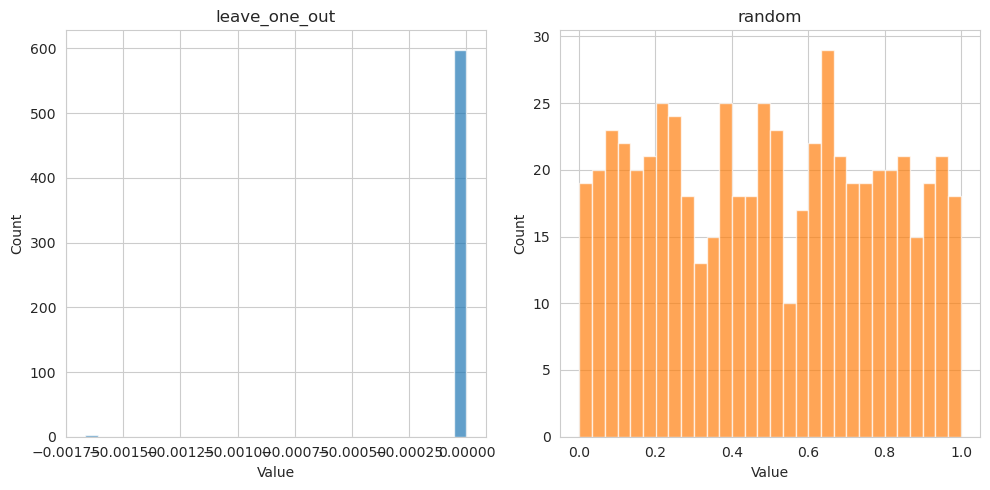

In [59]:
from utils.plotting import plot_data_valuation

# Plot the valuation histograms
fig = plot_data_valuation(valuation_results, DATASET_NAME, OUTPUT_DIR)

# Display a summary of the values for each method
for method, result in valuation_results.items():
    print(f"\n{method} value statistics:")
    print(f"Mean: {np.mean(result.values):.4f}")
    print(f"Min: {np.min(result.values):.4f}")
    print(f"Max: {np.max(result.values):.4f}")
    print(f"Std: {np.std(result.values):.4f}")

In [43]:
# Check how many values each method produced
print({k: len(v.values) for k, v in valuation_results.items()})

# Print first 5 values for each method
print({k: v.values[:5] for k, v in valuation_results.items()})

{'leave_one_out': 600, 'random': 600, 'least_core': 600, 'tmc_shapley': 600}
{'leave_one_out': array([0., 0., 0., 0., 0.]), 'random': array([0.21412644, 0.37418315, 0.4394856 , 0.67122231, 0.25251374]), 'least_core': array([ 1.16643177e-15, -3.91566428e-17,  2.19358554e-15,  9.12884950e-16,
        4.41003437e-16]), 'tmc_shapley': array([0., 0., 0., 0., 0.])}


In [40]:
values = valuation_results[method].values

In [39]:
print("Method:", method)
print("Valuation object:", type(valuation_results[method]))
print("Valuation result sample:", valuation_results[method])

In [44]:
# Test small subset scoring
utility = create_utility(X_train, y_train, X_test, y_test)
print("Score full dataset:", utility(list(range(len(X_train)))))
print("Score first 5 points:", utility(list(range(5))))

Score full dataset: 0.0
Score first 5 points: 0.0
